# Import the libraries we need

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

OUTPUT_DIR = Path("solarguard_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 30)

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.1.3


In [5]:
df_raw = pd.read_csv('/content/Laghouat_2022_final.csv')

print("Dataset loaded successfully!")
print("Shape:", df_raw.shape)

Dataset loaded successfully!
Shape: (4368, 14)


In [6]:
display(df_raw.head())
print("\nColumn names:")
print(df_raw.columns.tolist())

,datetime,dust_density_measured_gm2,dust_density_reconstructed_PCHIP_gm2,temp_amb_C,T_cell_C,G_POA_Wm2,RH_pct,wind_speed_ms,cloud_cover_pct,precipitation_mm,P_clean_W,P_dusty_W,P_clean_norm,P_dusty_norm
0,17/02/2022 00:00,NaN,0.0,9.0,9.0,0.0,26,4.7,1,0.0,0.0,0.0,0.0,0.0
1,17/02/2022 01:00,NaN,0.0,8.1,8.1,0.0,33,4.5,0,0.0,0.0,0.0,0.0,0.0
2,17/02/2022 02:00,NaN,0.0,7.1,7.1,0.0,37,3.6,29,0.0,0.0,0.0,0.0,0.0
3,17/02/2022 03:00,NaN,0.0,5.5,5.5,0.0,44,2.6,31,0.0,0.0,0.0,0.0,0.0
4,17/02/2022 04:00,NaN,0.0,4.6,4.6,0.0,49,2.4,15,0.0,0.0,0.0,0.0,0.0



Column names:
['datetime', 'dust_density_measured_gm2', 'dust_density_reconstructed_PCHIP_gm2', 'temp_amb_C', 'T_cell_C', 'G_POA_Wm2', 'RH_pct', 'wind_speed_ms', 'cloud_cover_pct', 'precipitation_mm', 'P_clean_W', 'P_dusty_W', 'P_clean_norm', 'P_dusty_norm']


In [7]:
schema = pd.DataFrame({
    "column": df_raw.columns,
    "data_type": [str(df_raw[c].dtype) for c in df_raw.columns],
    "non_null_count": [df_raw[c].notna().sum() for c in df_raw.columns],
    "missing_count": [df_raw[c].isna().sum() for c in df_raw.columns],
    "missing_percentage": [
        df_raw[c].isna().mean() * 100 for c in df_raw.columns
    ],
    "unique_values": [df_raw[c].nunique() for c in df_raw.columns]
})

display(schema)

,column,data_type,non_null_count,missing_count,missing_percentage,unique_values
0,datetime,object,4368,0,0.000000,4368
1,dust_density_measured_gm2,float64,48,4320,98.901099,48
2,dust_density_reconstructed_PCHIP_gm2,float64,4368,0,0.000000,4202
3,temp_amb_C,float64,4368,0,0.000000,404
4,T_cell_C,float64,4368,0,0.000000,688
5,G_POA_Wm2,float64,4368,0,0.000000,2305
6,RH_pct,int64,4368,0,0.000000,94
7,wind_speed_ms,float64,4368,0,0.000000,137
8,cloud_cover_pct,int64,4368,0,0.000000,101
9,precipitation_mm,float64,4368,0,0.000000,22


# Fix the datetime column and audit time continuity

In [8]:
df = df_raw.copy()

df["datetime"] = pd.to_datetime(
    df["datetime"],
    format="%d/%m/%Y %H:%M",
    errors="coerce"
)

invalid_dates = df["datetime"].isna().sum()
duplicate_timestamps = df["datetime"].duplicated().sum()

df = df.sort_values("datetime").reset_index(drop=True)

print("Invalid timestamps:", invalid_dates)
print("Duplicate timestamps:", duplicate_timestamps)
print("First timestamp:", df["datetime"].min())
print("Last timestamp:", df["datetime"].max())

valid_times = pd.DatetimeIndex(
    df["datetime"].dropna().unique()
).sort_values()

expected_times = pd.date_range(
    start=valid_times.min(),
    end=valid_times.max(),
    freq="h"
)

missing_hours = expected_times.difference(valid_times)

print("Unique observed timestamps:", len(valid_times))
print("Expected hourly timestamps:", len(expected_times))
print("Missing hourly timestamps:", len(missing_hours))

Invalid timestamps: 0
Duplicate timestamps: 0
First timestamp: 2022-02-17 00:00:00
Last timestamp: 2022-08-17 23:00:00
Unique observed timestamps: 4368
Expected hourly timestamps: 4368
Missing hourly timestamps: 0


# Missing values and duplicates

In [9]:
exact_duplicates = df_raw.duplicated().sum()

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean() * 100
}).sort_values("missing_percentage", ascending=False)

print("Exact duplicate rows:", exact_duplicates)
display(missing_summary)

Exact duplicate rows: 0


,missing_count,missing_percentage
dust_density_measured_gm2,4320,98.901099
datetime,0,0.000000
dust_density_reconstructed_PCHIP_gm2,0,0.000000
temp_amb_C,0,0.000000
T_cell_C,0,0.000000
G_POA_Wm2,0,0.000000
RH_pct,0,0.000000
wind_speed_ms,0,0.000000
cloud_cover_pct,0,0.000000
precipitation_mm,0,0.000000


# visualizing missing values

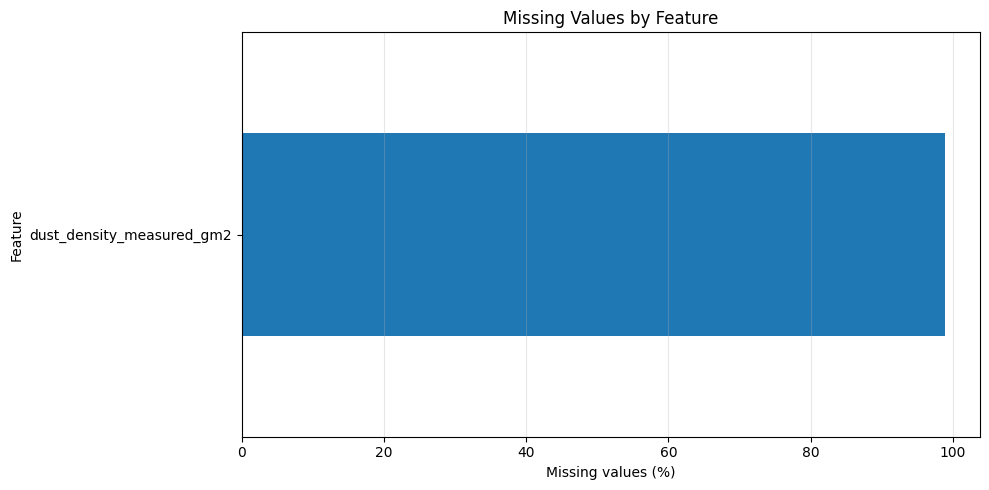

In [10]:
missing_pct = (
    df.isna().mean()
    .mul(100)
    .sort_values(ascending=False)
)

missing_pct = missing_pct[missing_pct > 0]

plt.figure(figsize=(10, 5))
missing_pct.sort_values().plot(kind="barh")

plt.title("Missing Values by Feature")
plt.xlabel("Missing values (%)")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Observation — Missing Values by Feature**

- Only one feature has missing data: `dust_density_measured_gm2`, at about **98.9%** missing (just 48 of 4,368 hourly rows are real measurements).
- Every other column is complete, so no imputation is needed for weather or power variables.
- The measured dust values are sparse spot readings. This is why the dataset also carries `dust_density_reconstructed_PCHIP_gm2`, which fills every hour by interpolation. Use the reconstructed column for modelling, and treat the measured one as ground truth for validating it only.

In [11]:
range_rules = {
    "G_POA_Wm2": (0, None),
    "RH_pct": (0, 100),
    "cloud_cover_pct": (0, 100),
    "wind_speed_ms": (0, None),
    "precipitation_mm": (0, None),
    "P_clean_W": (0, None),
    "P_dusty_W": (0, None),
    "dust_density_measured_gm2": (0, None),
    "dust_density_reconstructed_PCHIP_gm2": (0, None)
}

range_results = []

for column, (lower, upper) in range_rules.items():

    if column not in df.columns:
        continue

    values = pd.to_numeric(df[column], errors="coerce")

    invalid = pd.Series(False, index=df.index)

    if lower is not None:
        invalid |= values < lower

    if upper is not None:
        invalid |= values > upper

    range_results.append({
        "feature": column,
        "invalid_count": int(invalid.sum()),
        "invalid_percentage": invalid.mean() * 100
    })

range_results = pd.DataFrame(range_results)

display(range_results)

,feature,invalid_count,invalid_percentage
0,G_POA_Wm2,0,0.0
1,RH_pct,0,0.0
2,cloud_cover_pct,0,0.0
3,wind_speed_ms,0,0.0
4,precipitation_mm,0,0.0
5,P_clean_W,0,0.0
6,P_dusty_W,0,0.0
7,dust_density_measured_gm2,0,0.0
8,dust_density_reconstructed_PCHIP_gm2,0,0.0


# Descriptive statistics

In [12]:
numeric_df = df.select_dtypes(include=np.number)

stats = numeric_df.describe().T

stats["median"] = numeric_df.median()
stats["variance"] = numeric_df.var()
stats["skewness"] = numeric_df.skew()
stats["kurtosis"] = numeric_df.kurt()
stats["zero_count"] = (numeric_df == 0).sum()
stats["zero_percentage"] = (numeric_df == 0).mean() * 100

display(stats.round(3))

,count,mean,std,min,25%,50%,75%,max,median,variance,skewness,kurtosis,zero_count,zero_percentage
dust_density_measured_gm2,48.0,14.422,6.166,0.0,11.119,17.556,19.083,22.541,17.556,38.021,-0.909,-0.431,1,0.023
dust_density_reconstructed_PCHIP_gm2,4368.0,14.598,5.998,0.0,11.129,17.620,18.966,22.541,17.620,35.973,-0.896,-0.468,16,0.366
temp_amb_C,4368.0,23.145,10.053,-0.6,14.300,23.900,31.600,42.300,23.900,101.064,-0.088,-1.115,2,0.046
T_cell_C,4368.0,29.913,16.588,-0.6,16.900,27.800,38.300,72.000,27.800,275.164,0.634,-0.308,1,0.023
G_POA_Wm2,4368.0,216.562,346.305,0.0,0.000,16.840,223.015,1052.640,16.840,119927.004,1.436,0.421,2001,45.810
RH_pct,4368.0,33.269,22.304,5.0,16.000,26.000,46.000,100.000,26.000,497.484,0.955,-0.149,0,0.000
wind_speed_ms,4368.0,4.268,2.461,0.0,2.500,3.800,5.600,14.200,3.800,6.054,0.993,0.903,1,0.023
cloud_cover_pct,4368.0,34.000,39.664,0.0,0.000,12.000,74.000,100.000,12.000,1573.266,0.691,-1.216,1541,35.279
precipitation_mm,4368.0,0.019,0.168,0.0,0.000,0.000,0.000,6.000,0.000,0.028,17.728,457.612,4215,96.497
P_clean_W,4368.0,16.222,25.286,0.0,0.000,1.435,18.502,80.290,1.435,639.388,1.385,0.290,2037,46.635


# Analyze power distributions

###How does solar power generation change with solar irradiance and weather conditions?

Total records: 4368
Daylight-like records: 2134
Low-irradiance records: 2234


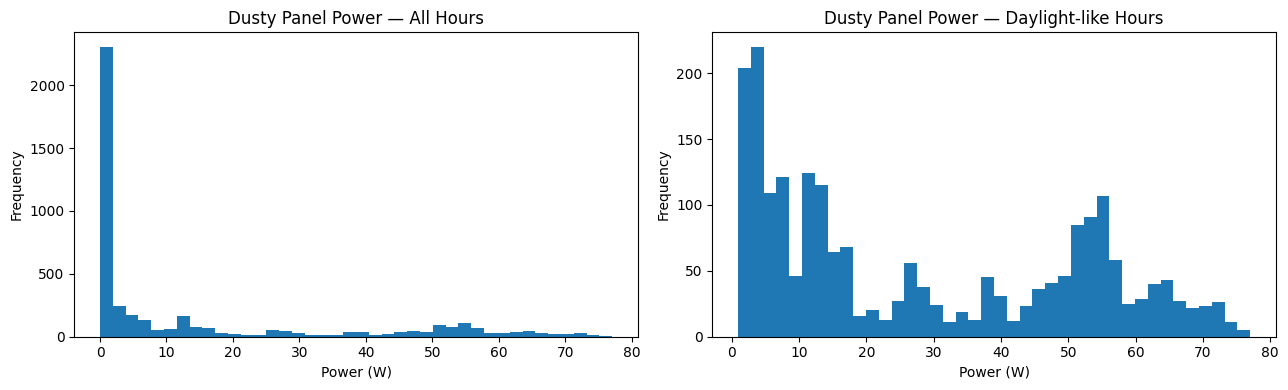

In [13]:
day_mask = df["G_POA_Wm2"] > 20

print("Total records:", len(df))
print("Daylight-like records:", int(day_mask.sum()))
print("Low-irradiance records:", int((~day_mask).sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(
    df["P_dusty_W"].dropna(),
    bins=40
)
axes[0].set_title("Dusty Panel Power — All Hours")
axes[0].set_xlabel("Power (W)")
axes[0].set_ylabel("Frequency")

axes[1].hist(
    df.loc[day_mask, "P_dusty_W"].dropna(),
    bins=40
)
axes[1].set_title("Dusty Panel Power — Daylight-like Hours")
axes[1].set_xlabel("Power (W)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

**Observation — Dusty Panel Power Distributions**

- **All hours (left):** a huge spike at ~0 W (about 2,300 of 4,368 rows, over half the data). That is nighttime, when there is no sunlight. The distribution is heavily right-skewed and zero-inflated.
- **Daylight-like hours, G > 20 W/m² (right):** once night is removed, the shape is multimodal. There is a large cluster at low power (0–15 W: dawn, dusk and cloudy hours) and a second broad peak around **50–57 W** (clear midday sun), with a thinner tail up to ~77 W.
- Takeaway: the night zeros distort any summary statistic or model fitted on all hours, so daylight filtering (or an explicit day/night feature) is justified. Power is not normally distributed, so avoid methods that assume normality.

# Time-series analysis

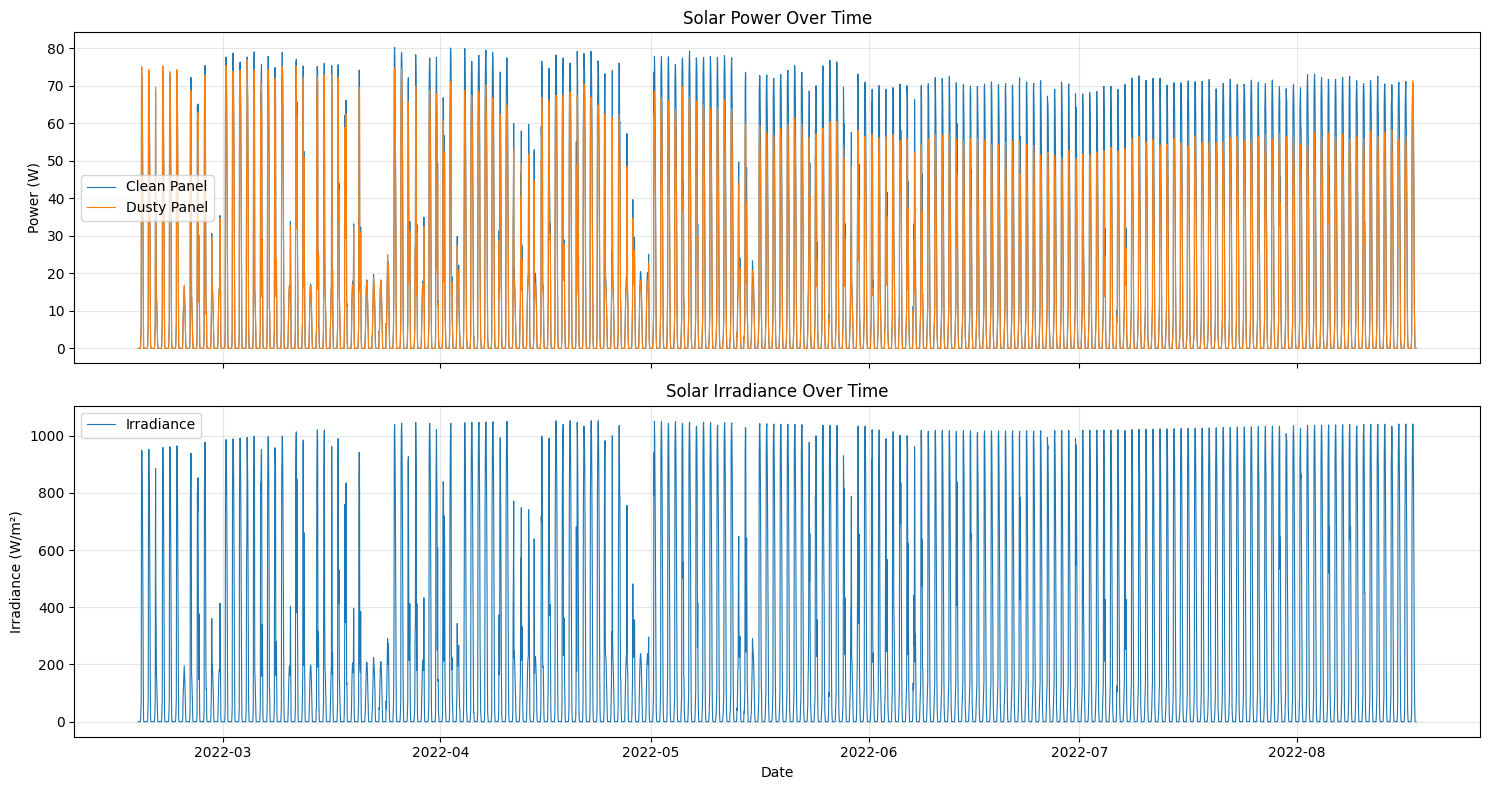

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

axes[0].plot(
    df["datetime"],
    df["P_clean_W"],
    label="Clean Panel",
    linewidth=0.8
)

axes[0].plot(
    df["datetime"],
    df["P_dusty_W"],
    label="Dusty Panel",
    linewidth=0.8
)

axes[0].set_title("Solar Power Over Time")
axes[0].set_ylabel("Power (W)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    df["datetime"],
    df["G_POA_Wm2"],
    label="Irradiance",
    linewidth=0.8
)

axes[1].set_title("Solar Irradiance Over Time")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Irradiance (W/m²)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Observation — Solar Power and Irradiance Over Time**

- Both panels follow a clear **daily cycle** (the dense spikes), and power tracks irradiance closely in shape. Irradiance is the main driver of output.
- **Late Feb to April:** both power and irradiance are irregular, with many low peaks. These are cloudier or less stable days. Peak irradiance climbs to ~1,000 W/m² by spring.
- **From May onward:** irradiance peaks are steady at about 1,000–1,050 W/m² (clear desert summer).
- **Clean vs dusty:** the two curves overlap in February to March, but from about **May** the dusty panel's peaks sit visibly lower, and the gap widens through July and August (clean ~70–73 W vs dusty ~55–58 W) even though irradiance is unchanged. That points to dust accumulation, not weather, as the cause.

P_clean_W         P_dusty_W          G_POA_Wm2        
                 mean    max       mean    max        mean     max
datetime                                                          
2022-02-17  16.000417  72.97  16.311250  75.12  203.115000  948.87
2022-02-18  16.080417  73.29  16.332083  74.40  203.966250  952.10
2022-02-19   7.695000  68.93   7.860000  69.63   93.767917  885.83
2022-02-20  16.105833  73.59  16.411250  75.36  205.647500  958.51
2022-02-21  16.238750  72.90  16.313750  73.80  206.795833  961.70

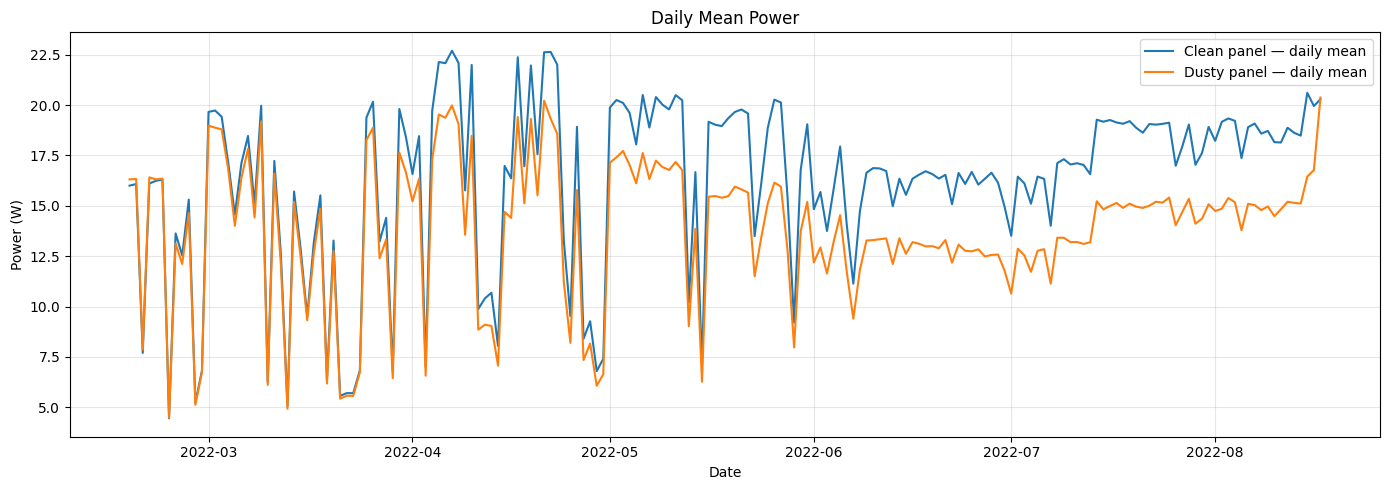

In [15]:
daily = (
    df.set_index("datetime")
      .resample("D")
      .agg({
          "P_clean_W": ["mean", "max"],
          "P_dusty_W": ["mean", "max"],
          "G_POA_Wm2": ["mean", "max"]
      })
)

display(daily.head())

plt.figure(figsize=(14, 5))

plt.plot(
    daily.index,
    daily[("P_clean_W", "mean")],
    label="Clean panel — daily mean"
)

plt.plot(
    daily.index,
    daily[("P_dusty_W", "mean")],
    label="Dusty panel — daily mean"
)

plt.title("Daily Mean Power")
plt.xlabel("Date")
plt.ylabel("Power (W)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Observation — Daily Mean Power (Clean vs Dusty)**

- Day-to-day swings (dips to ~5 W) are weather-driven and hit both panels equally, so the two lines move together.
- In Feb to March the lines are almost identical, so soiling losses are negligible early on (the dusty panel even edges slightly above on a few days, likely noise or measurement variation).
- The gap opens during **April to May** and settles at roughly **3–5 W** from June to August: clean around 16–19 W vs dusty around 12–15 W daily mean.
- The gap shrinks to near zero on the **last day (mid-August)**, which suggests a cleaning event or rain. This is worth checking against the precipitation column and dust density.

# Clean panel vs dusty panel

In [16]:
day = df.loc[
    day_mask,
    ["datetime", "G_POA_Wm2", "P_clean_W", "P_dusty_W"]
].copy()

day["power_gap_W"] = day["P_clean_W"] - day["P_dusty_W"]

day["relative_gap_pct"] = (
    day["power_gap_W"]
    / day["P_clean_W"].replace(0, np.nan)
) * 100

summary = pd.Series({
    "records": len(day),
    "mean_clean_power_W": day["P_clean_W"].mean(),
    "mean_dusty_power_W": day["P_dusty_W"].mean(),
    "mean_power_gap_W": day["power_gap_W"].mean(),
    "median_power_gap_W": day["power_gap_W"].median(),
    "mean_relative_gap_pct": day["relative_gap_pct"].mean()
})

display(summary.to_frame("value"))

,value
records,2134.000000
mean_clean_power_W,33.103205
mean_dusty_power_W,28.139452
mean_power_gap_W,4.963754
median_power_gap_W,2.040000
mean_relative_gap_pct,13.366669


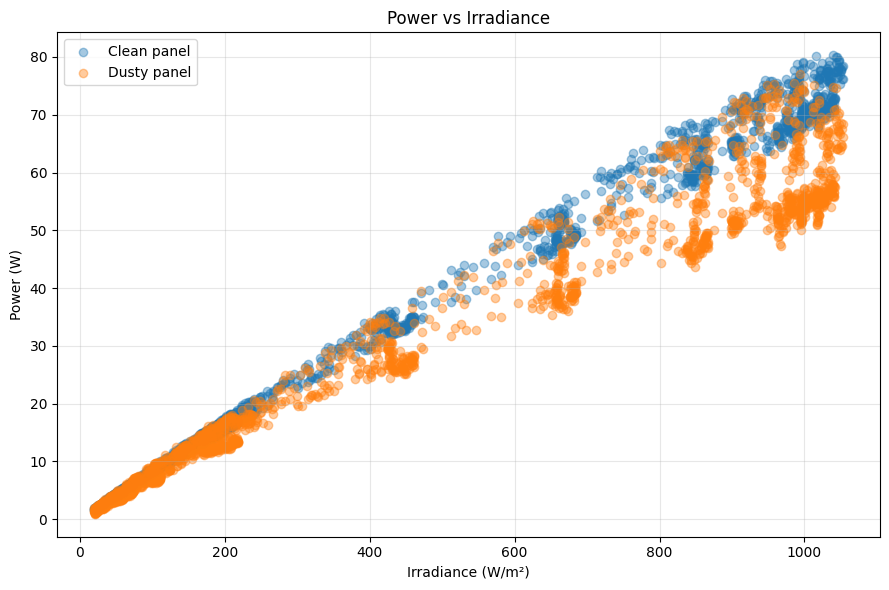

In [17]:
plt.figure(figsize=(9, 6))

plt.scatter(
    day["G_POA_Wm2"],
    day["P_clean_W"],
    alpha=0.4,
    label="Clean panel"
)

plt.scatter(
    day["G_POA_Wm2"],
    day["P_dusty_W"],
    alpha=0.4,
    label="Dusty panel"
)

plt.xlabel("Irradiance (W/m²)")
plt.ylabel("Power (W)")
plt.title("Power vs Irradiance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Observation — Power vs Irradiance**

- Both panels show a near-linear, positive relationship between irradiance and power, which confirms irradiance as the dominant predictor.
- **Below ~300 W/m²** the clean and dusty points overlap almost perfectly. Dust costs very little at low light.
- **Above ~400 W/m²** the dusty points fall below the clean ones, and the spread grows with irradiance. At ~1,000 W/m² the clean panel reaches ~70–80 W while the dusty one is often only ~50–60 W. Soiling loss therefore grows with irradiance, in line with the summary stats (mean gap 4.96 W, median 2.04 W, ~13.4% relative).
- The dusty cloud shows several parallel **bands**, each corresponding to a different dust-accumulation level (a stepwise drop after soiling builds up and recovers after cleaning or rain). Dust level is a useful secondary feature on top of irradiance.

# Pearson and Spearman correlation

In [18]:
corr_columns = [
    "temp_amb_C",
    "T_cell_C",
    "G_POA_Wm2",
    "RH_pct",
    "wind_speed_ms",
    "cloud_cover_pct",
    "precipitation_mm",
    "P_clean_W",
    "P_dusty_W",
    "dust_density_reconstructed_PCHIP_gm2"
]

corr_columns = [
    c for c in corr_columns
    if c in df.columns
]

pearson_corr = df[corr_columns].corr(method="pearson")
spearman_corr = df[corr_columns].corr(method="spearman")

display(
    spearman_corr[["P_dusty_W"]]
    .sort_values("P_dusty_W", ascending=False)
)

,P_dusty_W
P_dusty_W,1.000000
P_clean_W,0.998787
G_POA_Wm2,0.993875
T_cell_C,0.666906
temp_amb_C,0.255872
wind_speed_ms,0.033995
dust_density_reconstructed_PCHIP_gm2,0.026279
precipitation_mm,-0.000278
cloud_cover_pct,-0.038565
RH_pct,-0.259379


###Which numerical features are most strongly associated with dusty-panel power output?

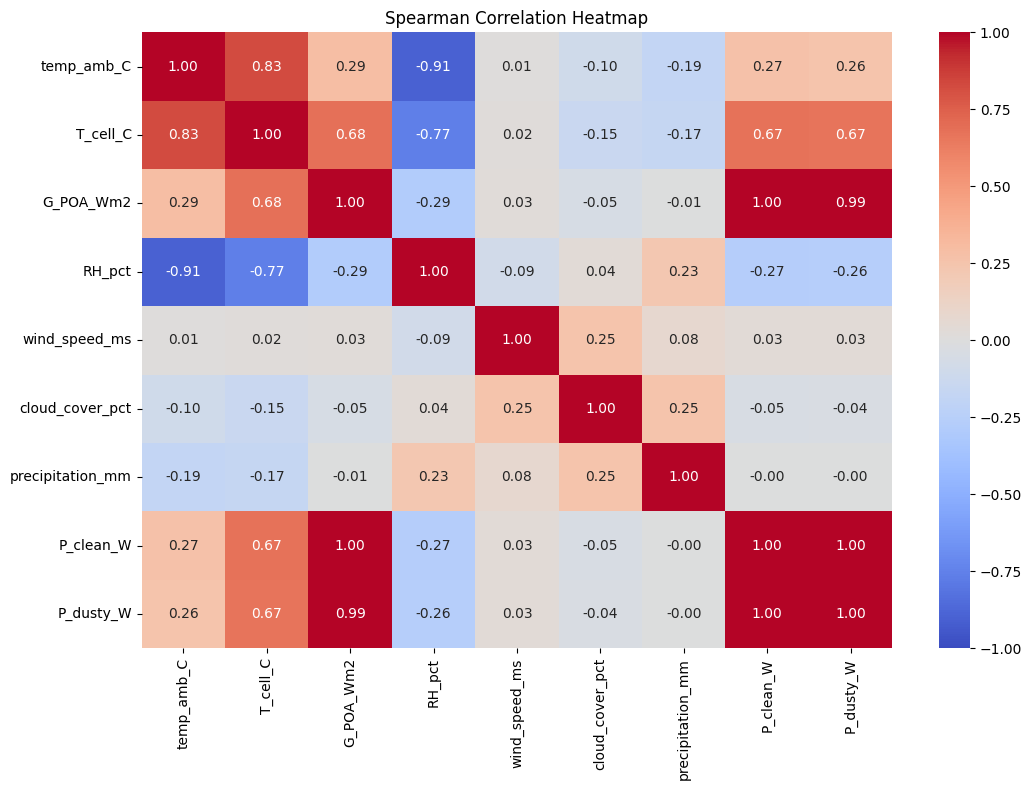

In [27]:
corr_columns = [
    "temp_amb_C",
    "T_cell_C",
    "G_POA_Wm2",
    "RH_pct",
    "wind_speed_ms",
    "cloud_cover_pct",
    "precipitation_mm",
    "P_clean_W",
    "P_dusty_W"
]

corr_matrix = df[corr_columns].corr(method="spearman")

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()

**Observation — Spearman Correlation Heatmap**

- **Irradiance dominates:** `G_POA_Wm2` correlates ≈ **0.99–1.00** with both `P_clean_W` and `P_dusty_W`. `P_clean_W` and `P_dusty_W` are themselves ≈ 1.00 correlated.
- **Cell temperature** is moderately correlated with power (0.67), but mostly because it rises with irradiance (0.68 with G).
- **Collinear weather block:** `temp_amb_C` and `T_cell_C` (0.83), and `RH_pct` vs `temp_amb_C` (−0.91) are strongly related. This agrees with the extremely high VIF values found later.
- **Wind, cloud cover and precipitation** are close to 0 with power (|ρ| ≤ 0.05). Their effect is indirect, acting through irradiance, and rank correlation can't see it.
- Takeaway: the heatmap is dominated by irradiance, and it can't isolate the dust effect because the clean and dusty power columns move together. A better dust signal is the *gap* (`P_clean − P_dusty`) or normalised power.

### Which numerical features are most strongly associated with dusty-panel power output?

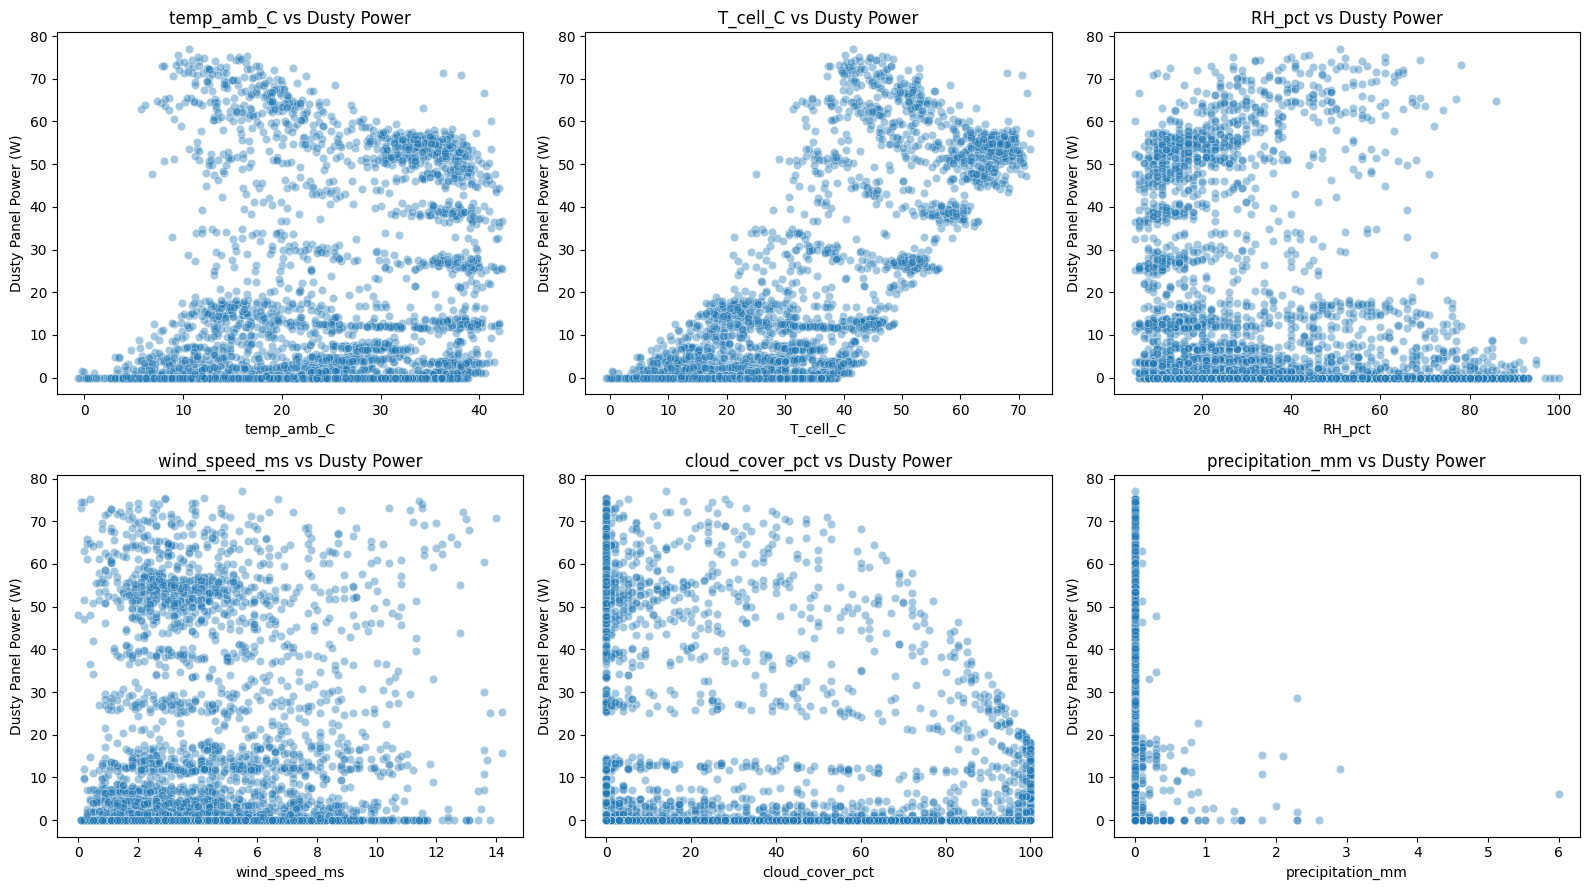

In [34]:
weather_columns = [
    "temp_amb_C",
    "T_cell_C",
    "RH_pct",
    "wind_speed_ms",
    "cloud_cover_pct",
    "precipitation_mm"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flat, weather_columns):
    sns.scatterplot(
        data=df,
        x=col,
        y="P_dusty_W",
        alpha=0.4,
        ax=ax
    )
    ax.set_title(f"{col} vs Dusty Power")
    ax.set_ylabel("Dusty Panel Power (W)")

plt.tight_layout()
plt.show()

**Observation — Weather Features vs Dusty Panel Power**

- **`temp_amb_C` and `T_cell_C`:** power increases with cell temperature, but this is **not** because heat boosts output. Hot cells coincide with strong sunlight. Panels actually lose efficiency when hot, which is hidden here by the irradiance effect. At 35–40 °C ambient there is a dense cluster at ~50–55 W (clear summer midday).
- **`RH_pct`:** the highest power occurs at low humidity (below ~40%), and power drops toward 0 near 100% RH. High humidity goes with night, dawn and overcast hours.
- **`wind_speed_ms`:** no clear trend. Points are spread across all power levels, with a dense cluster at 2–5 m/s and 50–55 W. Wind is a weak direct predictor.
- **`cloud_cover_pct`:** a clear **upper envelope that falls as cloud rises**. Maximum possible power declines toward 100% cloud, while low power also occurs at 0% cloud (night), so the relationship is one-sided.
- **`precipitation_mm`:** nearly all points are at 0 mm. Rain is rare in Laghouat, so there is too little data to judge its effect. Rain events may still matter as dust-cleaning events.
- The horizontal bands at ~12, ~27, ~39 and ~54 W show discrete clusters of repeated conditions (clear-sky midday at different seasons or dust levels).

# Multicollinearity using VIF

In [20]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.impute import SimpleImputer

vif_features = [
    c for c in [
        "temp_amb_C",
        "T_cell_C",
        "G_POA_Wm2",
        "RH_pct",
        "wind_speed_ms",
        "cloud_cover_pct",
        "precipitation_mm",
        "dust_density_reconstructed_PCHIP_gm2"
    ]
    if c in df.columns
]

vif_data = df[vif_features].replace(
    [np.inf, -np.inf],
    np.nan
)

imputer = SimpleImputer(strategy="median")

vif_values = imputer.fit_transform(vif_data)

vif_data = pd.DataFrame(
    vif_values,
    columns=vif_features
)

# Remove constant columns before calculating VIF.
vif_data = vif_data.loc[:, vif_data.nunique() > 1]

vif_results = pd.DataFrame({
    "feature": vif_data.columns,
    "VIF": [
        variance_inflation_factor(
            vif_data.to_numpy(),
            i
        )
        for i in range(vif_data.shape[1])
    ]
}).sort_values("VIF", ascending=False)

display(vif_results)

,feature,VIF
1,T_cell_C,605701.178180
2,G_POA_Wm2,257797.888282
0,temp_amb_C,222521.422407
3,RH_pct,4.477558
7,dust_density_reconstructed_PCHIP_gm2,2.756869
5,cloud_cover_pct,1.204820
4,wind_speed_ms,1.090213
6,precipitation_mm,1.064599


# Mutual Information

In [21]:
from sklearn.feature_selection import mutual_info_regression

mi_features = [
    c for c in [
        "temp_amb_C",
        "T_cell_C",
        "G_POA_Wm2",
        "RH_pct",
        "wind_speed_ms",
        "cloud_cover_pct",
        "precipitation_mm",
        "dust_density_reconstructed_PCHIP_gm2"
    ]
    if c in df.columns
]

mi_data = df[mi_features + ["P_dusty_W"]].copy()

mi_data = mi_data.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

X_mi = mi_data[mi_features]
y_mi = mi_data["P_dusty_W"]

mi_scores = mutual_info_regression(
    X_mi,
    y_mi,
    random_state=RANDOM_STATE
)

mi_results = pd.DataFrame({
    "feature": mi_features,
    "mutual_information": mi_scores
}).sort_values(
    "mutual_information",
    ascending=False
)

display(mi_results)

,feature,mutual_information
2,G_POA_Wm2,1.974246
1,T_cell_C,0.701630
7,dust_density_reconstructed_PCHIP_gm2,0.277370
0,temp_amb_C,0.276197
5,cloud_cover_pct,0.200878
3,RH_pct,0.141224
4,wind_speed_ms,0.041136
6,precipitation_mm,0.011137


# Outlier detection and investigation

In [22]:
outlier_features = [
    c for c in [
        "G_POA_Wm2",
        "P_clean_W",
        "P_dusty_W",
        "temp_amb_C",
        "T_cell_C",
        "wind_speed_ms",
        "precipitation_mm"
    ]
    if c in df.columns
]

outlier_summary = []

for column in outlier_features:

    values = df[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    flagged = (
        (df[column] < lower_bound)
        | (df[column] > upper_bound)
    )

    outlier_summary.append({
        "feature": column,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "flagged_count": int(flagged.sum()),
        "flagged_percentage": flagged.mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(
    outlier_summary.sort_values(
        "flagged_percentage",
        ascending=False
    )
)

,feature,lower_bound,upper_bound,flagged_count,flagged_percentage
0,G_POA_Wm2,-334.52250,557.53750,831,19.024725
1,P_clean_W,-27.75375,46.25625,819,18.750000
2,P_dusty_W,-25.59750,42.66250,740,16.941392
6,precipitation_mm,0.00000,0.00000,153,3.502747
5,wind_speed_ms,-2.15000,10.25000,115,2.632784
4,T_cell_C,-15.20000,70.40000,10,0.228938
3,temp_amb_C,-11.65000,57.55000,0,0.000000


### Which power and environmental measurements contain unusually extreme values that require investigation?

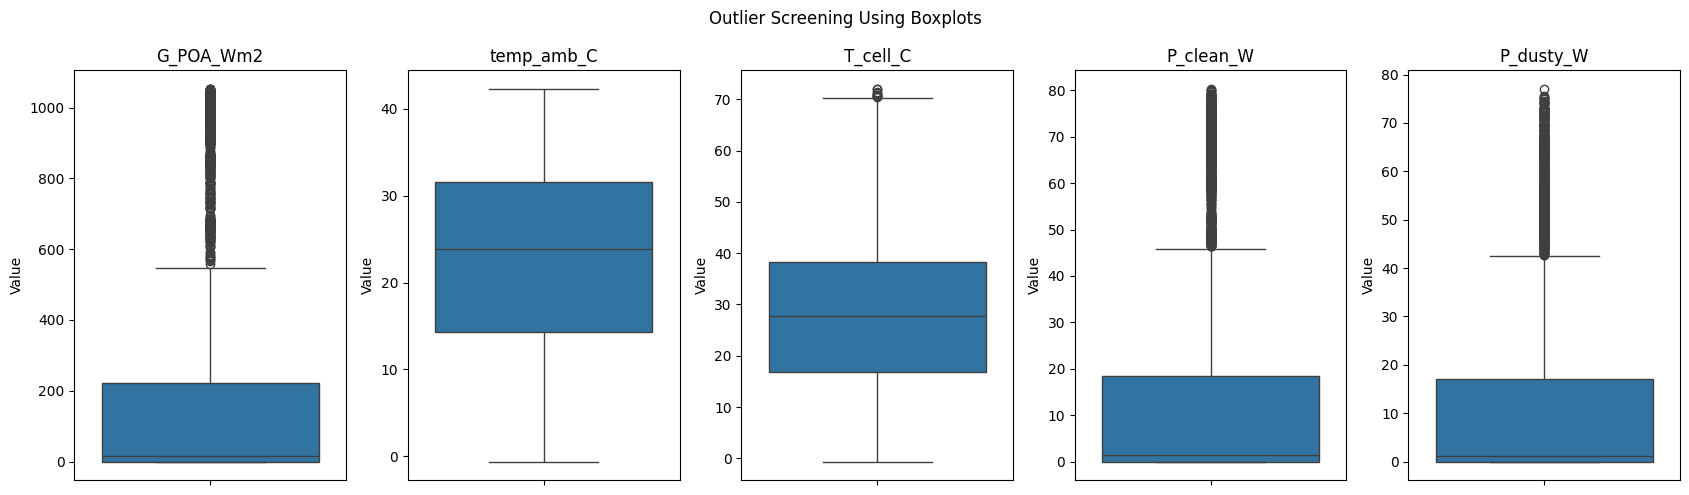

In [28]:
box_columns = [
    "G_POA_Wm2",
    "temp_amb_C",
    "T_cell_C",
    "P_clean_W",
    "P_dusty_W"
]

fig, axes = plt.subplots(1, len(box_columns), figsize=(17, 5))

for ax, col in zip(axes, box_columns):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Value")

plt.suptitle("Outlier Screening Using Boxplots")
plt.tight_layout()
plt.show()

**Observation — Outlier Screening (Boxplots)**

- **`G_POA_Wm2`, `P_clean_W`, `P_dusty_W`:** many points above the whiskers (~830, ~820 and ~740 flagged by IQR). The median and box sit near 0 because more than half the rows are night. As a result, ordinary daytime values (600–1,050 W/m² and 45–80 W) are flagged as "outliers".
- These are **valid daytime peaks, not errors**. The IQR rule is a poor fit for zero-inflated data, and the notebook's own check (no records with high irradiance but unusually low power) found 0 review candidates. Keep them.
- **`T_cell_C`:** only a handful of points just above ~70 °C, which is plausible for cells under direct summer sun.
- **`temp_amb_C`:** no outliers, with a median of about 24 °C and a range of roughly −1 to 42 °C.
- Takeaway: do not remove or clip these values. If outliers matter, assess them on daylight rows only.

In [23]:
high_irradiance = df["G_POA_Wm2"].quantile(0.90)
low_power = df["P_dusty_W"].quantile(0.10)

review_candidates = df[
    (df["G_POA_Wm2"] >= high_irradiance)
    & (df["P_dusty_W"] <= low_power)
].copy()

print("Review candidates:", len(review_candidates))

display(
    review_candidates[
        [
            "datetime",
            "G_POA_Wm2",
            "P_dusty_W",
            "P_clean_W",
            "T_cell_C"
        ]
    ].head(10)
)

Review candidates: 0


,datetime,G_POA_Wm2,P_dusty_W,P_clean_W,T_cell_C


# Preprocessing decisions and time-based split

In [24]:
df_model = df.sort_values("datetime").copy()

# Create time features.
df_model["hour"] = df_model["datetime"].dt.hour
df_model["day_of_week"] = df_model["datetime"].dt.dayofweek
df_model["day_of_year"] = df_model["datetime"].dt.dayofyear

# Cyclical encoding for time features.
df_model["hour_sin"] = np.sin(
    2 * np.pi * df_model["hour"] / 24
)

df_model["hour_cos"] = np.cos(
    2 * np.pi * df_model["hour"] / 24
)

# Past power observations.
df_model["P_dusty_lag_1h"] = df_model["P_dusty_W"].shift(1)
df_model["P_dusty_lag_24h"] = df_model["P_dusty_W"].shift(24)

# Target: dusty-panel power 24 rows in the future.
df_model["target_P_dusty_24h_ahead"] = (
    df_model["P_dusty_W"].shift(-24)
)

display(
    df_model[
        [
            "datetime",
            "P_dusty_W",
            "P_dusty_lag_1h",
            "P_dusty_lag_24h",
            "target_P_dusty_24h_ahead"
        ]
    ].head(30)
)

,datetime,P_dusty_W,P_dusty_lag_1h,P_dusty_lag_24h,target_P_dusty_24h_ahead
0,2022-02-17 00:00:00,0.00,NaN,NaN,0.00
1,2022-02-17 01:00:00,0.00,0.00,NaN,0.00
2,2022-02-17 02:00:00,0.00,0.00,NaN,0.00
3,2022-02-17 03:00:00,0.00,0.00,NaN,0.00
4,2022-02-17 04:00:00,0.00,0.00,NaN,0.00
5,2022-02-17 05:00:00,0.00,0.00,NaN,0.00
6,2022-02-17 06:00:00,0.00,0.00,NaN,0.00
7,2022-02-17 07:00:00,0.00,0.00,NaN,0.00
8,2022-02-17 08:00:00,0.45,0.00,NaN,0.80
9,2022-02-17 09:00:00,3.45,0.45,NaN,3.83
